<a href="https://colab.research.google.com/github/FisumTeshome/AddisSoftware/blob/main/YOLOv8FineTuning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Before running this code, ensure you have:
# 1. A GPU runtime: Go to Runtime -> Change runtime type -> Select GPU.
# 2. Uploaded your UNZIPPED dataset folder 'Yolo_dataset.v1i.yolov8-obb' directly to your Colab session storage.
#    (Click the folder icon on the left -> Drag and drop your folder into the files section, or upload its contents)

!pip install ultralytics
# Install required packages
from ultralytics import YOLO
import os
import torch
import yaml # To inspect data.yaml if needed

def check_dataset_existence_colab(dataset_base_path):
    """
    Checks if the unzipped dataset folder exists in the expected Colab location.
    """
    if not os.path.exists(dataset_base_path):
        print(f"Error: Unzipped dataset folder not found at {dataset_base_path}")
        print("Please ensure your folder 'Yolo_dataset.v1i.yolov8-obb' is directly uploaded to /content/.")
        return False
    print(f"Found dataset at: {dataset_base_path}")
    return True

def check_data_yaml_structure(dataset_base_path):
    """
    Helper function to check the data.yaml structure for fine-tuning.
    Ensures 'nc' is 90 and 'names' has exactly 90 entries.
    """
    dataset_yaml_path = os.path.join(dataset_base_path, 'data.yaml')
    print(f"\nChecking data.yaml structure at: {dataset_yaml_path}")
    if not os.path.exists(dataset_yaml_path):
        print(f"Error: data.yaml not found at {dataset_yaml_path}")
        return

    try:
        with open(dataset_yaml_path, 'r') as f:
            data_config = yaml.safe_load(f)
            print("Dataset config loaded successfully:")
            print(yaml.dump(data_config, indent=2))
            if 'names' not in data_config or not isinstance(data_config['names'], list):
                print("Warning: 'names' key not found or not a list in data.yaml. This is crucial for class names.")
            if 'train' not in data_config or 'val' not in data_config:
                print("Warning: 'train' or 'val' paths missing in data.yaml.")

            # Verify nc matches the number of names in your data.yaml for fine-tuning all 90 classes
            if 'nc' in data_config and 'names' in data_config:
                # CRITICAL: For fine-tuning a COCO-pretrained model with 10 new classes, nc MUST be 90.
                if data_config['nc'] != 90:
                    print(f"CRITICAL Warning: 'nc' is {data_config['nc']}. For fine-tuning a COCO-pretrained model with 10 custom classes, it MUST be 90 (80 COCO + 10 custom).")
                if len(data_config['names']) != 90:
                    print(f"CRITICAL Warning: Number of 'names' is {len(data_config['names'])}. For fine-tuning, it should be 90.")
            elif 'nc' not in data_config:
                print("CRITICAL Warning: 'nc' (number of classes) not found in data.yaml. It should be set to 90 for fine-tuning.")

            # Check relative paths in data.yaml against the base path
            print("\nChecking dataset paths within data.yaml...")
            for key in ['train', 'val', 'test']: # Changed 'valid' to 'val' to match common Ultralytics usage
                if key in data_config:
                    original_path = data_config[key]
                    resolved_path = os.path.abspath(os.path.join(os.path.dirname(dataset_yaml_path), original_path))
                    print(f"  {key} path: {original_path} (Resolved: {resolved_path})")
                    if not os.path.exists(resolved_path):
                        print(f"  CRITICAL: Resolved {key} path does NOT exist: {resolved_path}. Please check your data.yaml paths and ensure your dataset is fully extracted.")


    except Exception as e:
        print(f"An error occurred while checking data.yaml: {e}")


def train_model():
    # --- Colab specific dataset path setup ---
    # This path must match where your unzipped dataset folder is located in Colab.
    # If your folder name is different from 'Yolo_dataset.v1i.yolov8-obb', change it here.
    dataset_base_path = '/content/drive/MyDrive/datasets/Yolo_dataset_10class'

    if not check_dataset_existence_colab(dataset_base_path):
        print("Cannot proceed with training without dataset.")
        return

    # Check dataset structure (including data.yaml contents for 90 classes)
    check_dataset_structure(dataset_base_path)

    # --- CHANGE MADE HERE: Load the YOLOv8 Large model's pre-trained weights ---
    model = YOLO('yolov8l.pt') # Loads the pre-trained Large model

    # Colab typically provides 2 CPU cores for data loading
    num_workers = 2

    # Check if GPU is available
    device = 'cuda:0' if torch.cuda.is_available() else 'cpu'
    print(f"\nUsing device: {device}")

    # Define the dataset.yaml path for training
    dataset_yaml_path = os.path.join(dataset_base_path, 'data.yaml')

    print("\n--- Fine-tuning YOLOv8 Large Model (yolov8l.pt) on Google Colab ---")
    print(f"Model will be fine-tuned on data from: {dataset_yaml_path}")

    model.train(
        data=dataset_yaml_path, # Updated data path for Colab
        epochs=100,             # Epochs as per your preference
        imgsz=640,
        batch=16 if device == 'cuda:0' else 8, # Keep batch size, but be prepared to reduce if OutOfMemory.
                                                # For yolov8l.pt, you might need batch=8 or even 4 on typical Colab GPUs (T4).
        patience=50,            # Early stopping patience
        lr0=0.0001,             # Initial learning rate for fine-tuning
        lrf=0.01,               # Final learning rate fraction
        warmup_epochs=5,        # Warmup epochs
        cos_lr=True,            # Cosine LR scheduler
        freeze=15,              # Freeze first 15 layers for knowledge preservation
        dropout=0.2,            # Dropout rate
        mixup=0.1,              # Mixup for better generalization
        copy_paste=0.1,         # Copy-paste augmentation
        degrees=10.0,           # Random rotation augmentation
        scale=0.5,              # Random scale augmentation
        shear=2.0,              # Added shear augmentation
        perspective=0.0002,     # Added perspective augmentation
        hsv_h=0.015,            # Adjusted HSV augmentations
        hsv_s=0.7,
        hsv_v=0.4,
        fliplr=0.5,             # Standard horizontal flip
        mosaic=1.0,             # Mosaic augmentation enabled
        workers=num_workers,    # Use both CPU cores
        device=device,          # Use available device (GPU or CPU)
        cache='disk',           # Cache images on disk instead of RAM
        amp=True if device == 'cuda:0' else False, # Only use AMP with GPU
        name='combined_detection_yolov8l_finetune_colab', # New name for this training run in Colab
        close_mosaic=10         # Disable mosaic augmentation for final epochs
    )
    print("\nTraining complete. You can find the results in runs/detect/combined_detection_yolov8l_finetune_colab.")

if __name__ == "__main__":
    train_model()


Found dataset at: /content/drive/MyDrive/datasets/Yolo_dataset_10class


NameError: name 'check_dataset_structure' is not defined

In [ ]:
from ultralytics import YOLO
import os
import torch
import yaml # To inspect data.yaml if needed

def check_data_yaml_structure(dataset_base_path):
    """
    Checks the data.yaml structure, specifically for training from scratch.
    Ensures 'nc' is 10 and 'names' has exactly 10 entries.
    """
    dataset_yaml_path = os.path.join(dataset_base_path, 'data.yaml')
    print(f"\nChecking data.yaml structure at: {dataset_yaml_path}")
    if not os.path.exists(dataset_yaml_path):
        print(f"Error: data.yaml not found at {dataset_yaml_path}")
        print(f"Please ensure your unzipped dataset folder is at: {dataset_base_path}")
        return

    try:
        with open(dataset_yaml_path, 'r') as f:
            data_config = yaml.safe_load(f)
            print("Dataset config loaded successfully:")
            print(yaml.dump(data_config, indent=2))

            if 'names' not in data_config or not isinstance(data_config['names'], list):
                print("Warning: 'names' key not found or not a list in data.yaml. This is crucial for class names.")

            # Verify nc matches the number of names in your data.yaml
            if 'nc' in data_config and 'names' in data_config:
                if data_config['nc'] != 10:
                    print(f"CRITICAL Warning: 'nc' is {data_config['nc']}. For training from scratch on 10 classes, it MUST be 10.")
                if len(data_config['names']) != 10:
                    print(f"CRITICAL Warning: Number of 'names' is {len(data_config['names'])}. For training from scratch on 10 classes, it MUST be 10.")
            elif 'nc' not in data_config:
                print("CRITICAL Warning: 'nc' (number of classes) not found in data.yaml. It should be set to 10 for training from scratch.")

            # Additional check for relative paths in data.yaml (adjusting for Colab's /content/)
            print("\nChecking dataset paths within data.yaml...")
            for key in ['train', 'val', 'test']:
                if key in data_config:
                    original_path = data_config[key]
                    # Assuming paths like ../train/images
                    # We need to ensure these resolve correctly relative to the data.yaml file itself.
                    # If data.yaml is at /content/Yolo_dataset.v1i.yolov8-obb/data.yaml
                    # then ../train/images would resolve to /content/train/images
                    resolved_path = os.path.abspath(os.path.join(os.path.dirname(dataset_yaml_path), original_path))
                    print(f"  {key} path: {original_path} (Resolved: {resolved_path})")
                    if not os.path.exists(resolved_path):
                        print(f"  CRITICAL: Resolved {key} path does NOT exist: {resolved_path}. Please check your data.yaml paths and ensure your dataset is fully extracted.")

    except Exception as e:
        print(f"An error occurred while checking data.yaml: {e}")


def train_model_from_scratch_colab():
    # Since you uploaded the unzipped folder directly, it should be in /content/
    # If your folder has a different name, please update 'Yolo_dataset.v1i.yolov8-obb' below.
    dataset_base_path = '/content/drive/MyDrive/datasets/Yolo_dataset_10class'

    # Verify the unzipped folder exists
    if not os.path.exists(dataset_base_path):
        print(f"Error: Unzipped dataset folder not found at {dataset_base_path}")
        print("Please ensure your folder 'Yolo_dataset_10class' is located at '/content/datasets/'.")
        return

    print(f"Found dataset at: {dataset_base_path}")

    # --- Step 1: Check data.yaml structure ---
    check_data_yaml_structure(dataset_base_path)

    # Initialize the YOLOv8n model architecture from scratch.
    # We DO NOT use 'yolov8n.pt' here, as we are not loading pre-trained weights.
    # Instead, we load the model configuration file.
    model = YOLO('yolov8n.yaml') # This creates a model with random weights

    num_workers = 2 # Colab typically provides 2 CPU cores for data loading

    # Check if GPU is available
    device = 'cuda:0' if torch.cuda.is_available() else 'cpu'
    print(f"\nUsing device: {device}")

    # Define the dataset.yaml path for training
    dataset_yaml_path = os.path.join(dataset_base_path, 'data.yaml')

    print("\n--- Training YOLOv8 Model From Scratch on Google Colab (10 Custom Classes Only) ---")

    model.train(
        data=dataset_yaml_path,
        epochs=300,             # Increased epochs significantly for training from scratch
        imgsz=640,
        batch=16 if device == 'cuda:0' else 8,
        patience=75,            # Adjusted patience
        lr0=0.01,               # Higher initial learning rate for training from scratch
        lrf=0.01,               # Final learning rate fraction
        warmup_epochs=10,       # Increased warmup epochs
        cos_lr=True,            # Cosine LR scheduler
        freeze=0,               # All layers must be unfrozen when training from scratch
        dropout=0.2,            # Dropout rate
        mixup=0.1,              # Mixup augmentation
        copy_paste=0.1,         # Copy-paste augmentation
        degrees=10.0,           # Random rotation augmentation
        scale=0.5,              # Random scale augmentation
        shear=2.0,              # Add shear augmentation
        perspective=0.0002,     # Add perspective augmentation
        hsv_h=0.015,            # Adjust HSV augmentations
        hsv_s=0.7,
        hsv_v=0.4,
        fliplr=0.5,             # Standard horizontal flip
        mosaic=1.0,             # Mosaic augmentation enabled
        workers=num_workers,    # Use both CPU cores
        device=device,          # Use available device (GPU or CPU)
        cache='disk',           # Cache images on disk instead of RAM
        amp=True if device == 'cuda:0' else False, # Only use AMP with GPU
        name='yolov8n_from_scratch_colab_10_classes', # Unique name for this run in Colab
        close_mosaic=10,        # Disable mosaic augmentation for final epochs
    )
    print("\nTraining complete. You can find the results in runs/detect/yolov8n_from_scratch_colab_10_classes.")

if __name__ == "__main__":
    train_model_from_scratch_colab()

Found dataset at: /content/drive/MyDrive/datasets/Yolo_dataset_10class

Checking data.yaml structure at: /content/drive/MyDrive/datasets/Yolo_dataset_10class/data.yaml
Dataset config loaded successfully:
names:
  '0': person
  '1': car
  '2': chair
  '3': dining table
  '4': door
  '5': wall
  '6': street pole
  '7': stairs
  '8': bus
  '9': truck
nc: 10
test: test/images
train: train/images
val: valid/images


Checking dataset paths within data.yaml...
  train path: train/images (Resolved: /content/drive/MyDrive/datasets/Yolo_dataset_10class/train/images)
  test path: test/images (Resolved: /content/drive/MyDrive/datasets/Yolo_dataset_10class/test/images)

Using device: cuda:0

--- Training YOLOv8 Model From Scratch on Google Colab (10 Custom Classes Only) ---
Ultralytics 8.3.155 🚀 Python-3.11.13 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=disk, cfg=None, classes=

100%|██████████| 755k/755k [00:00<00:00, 107MB/s]

Overriding model.yaml nc=80 with nc=10

                   from  n    params  module                                       arguments                     
  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 
  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                
  2                  -1  1      7360  ultralytics.nn.modules.block.C2f             [32, 32, 1, True]             
  3                  -1  1     18560  ultralytics.nn.modules.conv.Conv             [32, 64, 3, 2]                
  4                  -1  2     49664  ultralytics.nn.modules.block.C2f             [64, 64, 2, True]             
  5                  -1  1     73984  ultralytics.nn.modules.conv.Conv             [64, 128, 3, 2]               
  6                  -1  2    197632  ultralytics.nn.modules.block.C2f             [128, 128, 2, True]           
  7                  -1  1    295424  ultralytic

YOLOv8n summary: 129 layers, 3,012,798 parameters, 3,012,782 gradients, 8.2 GFLOPs

Freezing layer 'model.22.dfl.conv.weight'
AMP: running Automatic Mixed Precision (AMP) checks...


100%|██████████| 5.35M/5.35M [00:00<00:00, 326MB/s]


AMP: checks passed ✅
train: Fast image access ✅ (ping: 0.5±0.2 ms, read: 0.0±0.0 MB/s, size: 22.7 KB)


train: Scanning /content/drive/MyDrive/datasets/Yolo_dataset_10class/train/labels... 1396 images, 0 backgrounds, 0 corrupt:  82%|████████▏ | 1396/1703 [21:01<04:18,  1.19it/s]

In [ ]:
import os

# List the contents of the /content/datasets/ directory
print("Contents of /content/drive/MyDrive/datasets/:")
try:
    for item in os.listdir('/content/drive/MyDrive/datasets/'):
        print(item)
except FileNotFoundError:
    print("/content/datasets/ directory not found.")

Contents of /content/drive/MyDrive/datasets/:
Yolo_dataset_10class


--- Loading DeepLabV3 ResNet50 (PyTorch) ---


Downloading: "https://download.pytorch.org/models/deeplabv3_resnet50_coco-cd0a2569.pth" to /root/.cache/torch/hub/checkpoints/deeplabv3_resnet50_coco-cd0a2569.pth
100%|██████████| 161M/161M [00:00<00:00, 190MB/s]


DeepLabV3 ResNet50 model loaded successfully!

Example image loaded from: https://github.com/pytorch/hub/raw/master/images/deeplab1.png
Using GPU for inference.


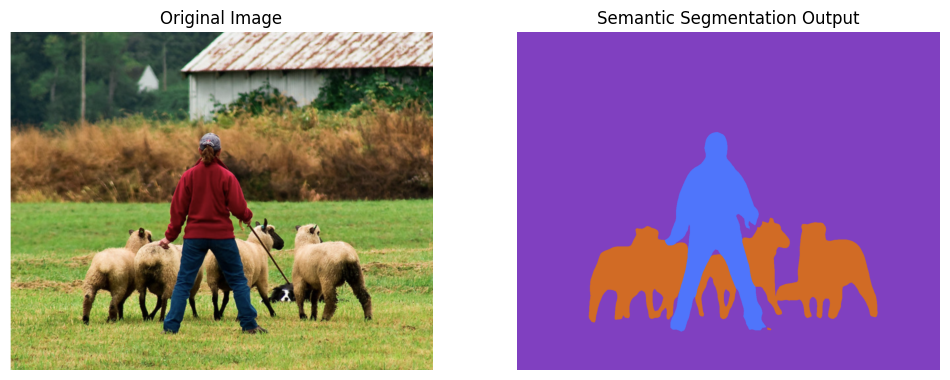


Pre-trained DeepLabV3 outputs pixel-level predictions. Each color represents a different class.
For your assistive app, you would fine-tune this model on your own dataset
with pixel-level annotations for your 10 obstacle classes (wall, stairs, etc.).
Then, you would process the output masks to identify and locate obstacles.


In [ ]:
# --- IMPORTANT SETUP FOR KAGGLE/COLAB ---
# 1. Run the following pip installs in a separate cell FIRST:
#    !pip install torchvision requests matplotlib
# 2. After running the pip installs, go to "Runtime" (in Google Colab) or "Kernel" (in Kaggle) -> "Restart runtime/kernel".
#    This is CRUCIAL for newly installed packages to be recognized.
# 3. Then, run this entire code block in a new cell.

import torch
import torchvision
import torchvision.transforms as T
from PIL import Image
import requests
from io import BytesIO
import matplotlib.pyplot as plt
import numpy as np


def load_and_test_deeplabv3_pytorch():
    """
    Loads a pre-trained DeepLabV3 model from torchvision and performs a sample inference.
    """
    print("--- Loading DeepLabV3 ResNet50 (PyTorch) ---")

    # Load a pre-trained DeepLabV3 model
    # You can choose different backbones:
    # torchvision.models.segmentation.deeplabv3_resnet50(pretrained=True)
    # torchvision.models.segmentation.deeplabv3_resnet101(pretrained=True)
    # torchvision.models.segmentation.deeplabv3_mobilenet_v3_large(pretrained=True)

    # Using ResNet50 for demonstration
    try:
        # Corrected line: Referencing through torchvision.models.segmentation
        model = torchvision.models.segmentation.deeplabv3_resnet50(weights='DEFAULT') # Use 'DEFAULT' for latest best weights
        model.eval() # Set the model to evaluation mode
        print("DeepLabV3 ResNet50 model loaded successfully!")
    except Exception as e:
        print(f"Error loading DeepLabV3 model: {e}")
        print("Please ensure you have an internet connection to download weights.")
        return

    # --- Prepare an example image for inference ---
    # You can replace this with your own image path
    img_url = "https://github.com/pytorch/hub/raw/master/images/deeplab1.png"
    try:
        response = requests.get(img_url)
        img = Image.open(BytesIO(response.content)).convert("RGB")
        print(f"\nExample image loaded from: {img_url}")
    except Exception as e:
        print(f"Error loading example image: {e}")
        print("Please ensure the image URL is accessible.")
        return

    # Define preprocessing transformations
    # DeepLabV3 expects images to be normalized with specific mean and std
    preprocess = T.Compose([
        T.ToTensor(),
        T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ])

    # Apply transformations and add a batch dimension
    input_tensor = preprocess(img)
    input_batch = input_tensor.unsqueeze(0) # create a mini-batch as expected by the model

    # Move to GPU if available
    if torch.cuda.is_available():
        input_batch = input_batch.to('cuda')
        model.to('cuda')
        print("Using GPU for inference.")
    else:
        print("Using CPU for inference.")

    # --- Perform Inference ---
    with torch.no_grad():
        output = model(input_batch)['out'][0]

    # Get the predicted segmentation mask
    # The output is logits, apply argmax to get class indices for each pixel
    output_predictions = output.argmax(0)

    # Convert the output predictions to a format for visualization
    # The pre-trained DeepLabV3 on Pascal VOC has 21 classes (including background)
    # Define a simple color map (Pascal VOC default colors are complex)
    # For visualization, we'll just assign a unique color to each detected class.

    # Create a reproducible color map for 21 classes + potentially more
    def create_pascal_voc_colormap(num_classes):
        cmap = np.zeros((num_classes, 3), dtype=np.uint8)
        for i in range(num_classes):
            r = ((i * 321) % 256 + 128) % 256
            g = ((i * 123) % 256 + 64) % 256
            b = ((i * 789) % 256 + 192) % 256
            cmap[i, :] = [r, g, b]
        return cmap

    # Get the class names (for Pascal VOC 20 classes + background)
    # Note: These are the classes the pre-trained model knows.
    # If fine-tuning for your 10 classes, these names would change based on your data.yaml.
    pascal_voc_classes = [
        '__background__', 'aeroplane', 'bicycle', 'bird', 'boat',
        'bottle', 'bus', 'car', 'cat', 'chair', 'cow',
        'diningtable', 'dog', 'horse', 'motorbike', 'person', 'pottedplant',
        'sheep', 'sofa', 'train', 'tvmonitor'
    ]

    cmap = create_pascal_voc_colormap(len(pascal_voc_classes))
    segmented_image = cmap[output_predictions.cpu().numpy()] # Apply colormap

    # --- Display Results ---
    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    plt.imshow(img)
    plt.title("Original Image")
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(segmented_image)
    plt.title("Semantic Segmentation Output")
    plt.axis('off')

    plt.show()

    print("\nPre-trained DeepLabV3 outputs pixel-level predictions. Each color represents a different class.")
    print("For your assistive app, you would fine-tune this model on your own dataset")
    print("with pixel-level annotations for your 10 obstacle classes (wall, stairs, etc.).")
    print("Then, you would process the output masks to identify and locate obstacles.")

if __name__ == "__main__":
    load_and_test_deeplabv3_pytorch()



In [ ]:
import torch
import torchvision.models.segmentation as segmentation_models
import os

def save_deeplabv3_model(model, save_path="deeplabv3_resnet50_fine_tuned.pth"):
    """
    Saves the state_dict (weights) of a PyTorch DeepLabV3 model to a file.

    Args:
        model (torch.nn.Module): The DeepLabV3 model instance you want to save.
        save_path (str): The filename (and optional path) to save the model to.
                         In Kaggle/Colab, this will typically save to /kaggle/working/
                         or /content/, which are the writable directories.
    """
    try:
        # Save only the model's state_dict (learned parameters)
        # This is generally preferred over saving the entire model object
        # as it's more flexible for loading into different model definitions later.
        torch.save(model.state_dict(), save_path)
        print(f"DeepLabV3 model weights saved successfully to: {save_path}")
    except Exception as e:
        print(f"Error saving model: {e}")

if __name__ == "__main__":
    print("--- Loading DeepLabV3 ResNet50 (PyTorch) for saving ---")

    # Load the pre-trained DeepLabV3 model
    # Ensure this matches the model you intend to save (e.g., if you fine-tuned it,
    # you would load your fine-tuned model here, not a fresh 'DEFAULT' one).
    try:
        # We are loading the pre-trained model as you just did successfully.
        # If you were to fine-tune this model later, you would load your
        # fine-tuned model here to save its updated weights.
        model = segmentation_models.deeplabv3_resnet50(weights='DEFAULT')
        model.eval() # Set to evaluation mode
        print("DeepLabV3 ResNet50 model loaded for saving.")
    except Exception as e:
        print(f"Error loading DeepLabV3 model for saving: {e}")
        print("Please ensure you have an internet connection to download weights if not cached.")
        # Exit if model cannot be loaded
        exit()

    # --- Specify the path where you want to save the model ---
    # In Kaggle/Colab, the current working directory is usually '/kaggle/working/' or '/content/'
    # You can provide a full path if you prefer a specific subdirectory.
    output_filename = "deeplabv3_resnet50_pretrained_coco.pth"

    # Save the model
    save_deeplabv3_model(model, output_filename)

    print("\nNext, download the '.pth' file from your Kaggle/Colab environment.")


--- Loading DeepLabV3 ResNet50 (PyTorch) for saving ---
DeepLabV3 ResNet50 model loaded for saving.
DeepLabV3 model weights saved successfully to: deeplabv3_resnet50_pretrained_coco.pth

Next, download the '.pth' file from your Kaggle/Colab environment.


In [ ]:
import os
import glob
import torch
import torchvision.transforms as T
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import torchvision.models.segmentation as segmentation_models

def create_pascal_voc_colormap(num_classes):
    """
    Creates a reproducible color map for visualization.
    """
    cmap = np.zeros((num_classes, 3), dtype=np.uint8)
    for i in range(num_classes):
        r = ((i * 321) % 256 + 128) % 256
        g = ((i * 123) % 256 + 64) % 256
        b = ((i * 789) % 256 + 192) % 256
        cmap[i, :] = [r, g, b]
    return cmap

def test_deeplabv3_on_folder(model, image_folder_path):
    """
    Tests a DeepLabV3 model on all images in a specified folder and displays results.

    Args:
        model (torch.nn.Module): The loaded DeepLabV3 model instance.
        image_folder_path (str): The path to the folder containing test images.
    """
    print(f"\n--- Testing DeepLabV3 model on images in: {image_folder_path} ---")

    # Get a list of image files in the folder
    image_files = glob.glob(os.path.join(image_folder_path, '*.jpg')) + \
                  glob.glob(os.path.join(image_folder_path, '*.png')) + \
                  glob.glob(os.path.join(image_folder_path, '*.jpeg'))

    if not image_files:
        print(f"No image files found in {image_folder_path}. Please check the path and file extensions.")
        return

    print(f"Found {len(image_files)} images to process.")

    # Define the same preprocessing transformations used during training/inference
    preprocess = T.Compose([
        T.ToTensor(),
        T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ])

    # Move model to GPU if available
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    model.to(device)
    model.eval() # Set the model to evaluation mode

    # Get the class names (for Pascal VOC 20 classes + background)
    pascal_voc_classes = [
        '__background__', 'aeroplane', 'bicycle', 'bird', 'boat',
        'bottle', 'bus', 'car', 'cat', 'chair', 'cow',
        'diningtable', 'dog', 'horse', 'motorbike', 'person', 'pottedplant',
        'sheep', 'sofa', 'train', 'tvmonitor'
    ]
    cmap = create_pascal_voc_colormap(len(pascal_voc_classes))

    for img_path in image_files:
        try:
            img = Image.open(img_path).convert("RGB")
            print(f"\nProcessing image: {os.path.basename(img_path)}")

            # Apply transformations and add a batch dimension
            input_tensor = preprocess(img)
            input_batch = input_tensor.unsqueeze(0).to(device) # create a mini-batch and move to device

            # --- Perform Inference ---
            with torch.no_grad():
                output = model(input_batch)['out'][0]

            # Get the predicted segmentation mask
            output_predictions = output.argmax(0)

            # Convert the output predictions to a format for visualization
            segmented_image = cmap[output_predictions.cpu().numpy()] # Apply colormap

            # --- Display Results ---
            plt.figure(figsize=(12, 6))

            plt.subplot(1, 2, 1)
            plt.imshow(img)
            plt.title(f"Original Image: {os.path.basename(img_path)}")
            plt.axis('off')

            plt.subplot(1, 2, 2)
            plt.imshow(segmented_image)
            plt.title("Semantic Segmentation Output")
            plt.axis('off')

            plt.show()

        except Exception as e:
            print(f"Error processing image {img_path}: {e}")
            continue # Continue to the next image if one fails


if __name__ == "__main__":
    print("--- Loading DeepLabV3 ResNet50 (PyTorch) for testing ---")

    # Load the pre-trained DeepLabV3 model
    # This should match the model you want to test (e.g., the one you just loaded or saved)
    try:
        # We will load the pre-trained COCO weights again for demonstration.
        # If you had fine-tuned, you would load your fine-tuned model here.
        loaded_model = segmentation_models.deeplabv3_resnet50(weights='DEFAULT')
        print("DeepLabV3 ResNet50 model loaded for testing.")
    except Exception as e:
        print(f"Error loading DeepLabV3 model for testing: {e}")
        print("Please ensure you have an internet connection or the weights file is available.")
        # Exit if model cannot be loaded
        exit()

    # --- Specify the path to your test images folder ---
    test_image_folder_path = '/content/drive/MyDrive/datasets/Yolo_dataset_10class/test/images'

    # Test the model on the images in the specified folder
    test_deeplabv3_on_folder(loaded_model, test_image_folder_path)

    print("\nFinished testing DeepLabV3 model on the test images.")